# Chương 2 — Preliminaries

**Người làm: Lê Sơn Trường.** Đối chiếu PDF D2L 1.0.3 trang 77–118.
Các ô code trong notebook cùng chương kiểm chứng những phép tính và thí nghiệm dưới đây.


Nguồn: [D2L chương 2](https://d2l.ai/chapter_preliminaries/index.html). Lời giải giữ số câu để đối chiếu PDF. Chạy **Run All**; mặc định đọc cache kết quả thật. Đổi `RECOMPUTE=True` để học lại bằng nguồn `.py` đi kèm.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
paths = [cwd, cwd / "bai_lam_Le_Son_Truong", cwd / "Buoi2" / "bai_lam_Le_Son_Truong",
         *[p / "Buoi2" / "bai_lam_Le_Son_Truong" for p in cwd.parents]]
BASE = next((p for p in paths if (p / "experiments.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook trong repository DeepL hoặc thư mục bài làm Buoi2.")
sys.path.insert(0, str(BASE))
from experiments import run_section, render_result

# False: đọc lại kết quả thật đã lưu. True: chạy lại các thí nghiệm (tốn thời gian).
RECOMPUTE = False
if RECOMPUTE:
    from data import prepare
    prepare()
print("Người làm: Lê Sơn Trường | D2L 1.0.3 | CPU, seed 42")


Người làm: Lê Sơn Trường | D2L 1.0.3 | CPU, seed 42


## 2.1 — Data Manipulation (2 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 77 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Run the code in this section. Change the conditional statementX == Y to X &lt; Y or X &gt;
Y, and then see what kind of tensor you can get.
2. Replace the two tensors that operate by element in the broadcasting mechanism with
other shapes, e.g., 3-dimensional tensors. Is the result the same as expected?
</pre>
</details>


### Câu 1

`X < Y` và `X > Y` so sánh từng phần tử, trả về tensor `torch.bool` cùng shape
sau broadcasting. Không trả về một boolean chung cho hai tensor. Notebook chạy
các thao tác tạo, reshape, indexing, nối, toán tử và so sánh của mục này.

### Câu 2

Ví dụ `(2,1,4) + (1,3,1)` cho shape `(2,3,4)`. So từ chiều cuối: hai kích thước
phải bằng nhau hoặc một bên bằng 1. `(2,3,4) + (2,2,4)` không tương thích ở
chiều giữa nên báo lỗi. Không tạo bản sao vật lý của mọi phần tử chỉ để broadcast.

In [2]:
result = run_section("2.1", recompute=RECOMPUTE)
render_result(result)

Broadcast (2, 1, 4) + (1, 3, 1) -> (2, 3, 4): [[[0, 1, 2, 3], [1, 2, 3, 4], [2, 3, 4, 5]], [[4, 5, 6, 7], [5, 6, 7, 8], [6, 7, 8, 9]]]
Index X[1,2]=6.0; sum=66.0; NumPy round-trip shape=(3, 4)
Slice assignment then in-place +=: [[14.0, 13.0, 16.0, 15.0], [13.0, 14.0, 15.0, 16.0], [12.0, 12.0, 12.0, 12.0]]; id preserved=True
Tensor scalar conversions: item=3.5, float=3.5


**tensor_operations**

,operation,result
0,X,"[[0.0, 1.0, 2.0, 3.0], [4.0, 5.0, 6.0, 7.0], [..."
1,Y,"[[2.0, 1.0, 4.0, 3.0], [1.0, 2.0, 3.0, 4.0], [..."
2,X+Y,"[[2.0, 2.0, 6.0, 6.0], [5.0, 7.0, 9.0, 11.0], ..."
3,X-Y,"[[-2.0, 0.0, -2.0, 0.0], [3.0, 3.0, 3.0, 3.0],..."
4,X*Y,"[[0.0, 1.0, 8.0, 9.0], [4.0, 10.0, 18.0, 28.0]..."
5,X/Y,"[[0.0, 1.0, 0.5, 1.0], [4.0, 2.5, 2.0, 1.75], ..."
6,X**Y,"[[0.0, 1.0, 16.0, 27.0], [4.0, 25.0, 216.0, 24..."
7,exp(X),"[[1.0, 2.7182817459106445, 7.389056205749512, ..."
8,X[-1],"[8.0, 9.0, 10.0, 11.0]"
9,X[1:3],"[[4.0, 5.0, 6.0, 7.0], [8.0, 9.0, 10.0, 11.0]]"


## 2.2 — Data Preprocessing (5 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 80 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Try loading datasets, e.g., Abalone from theUCI Machine Learning Repository50 and
inspect their properties. What fraction of them has missing values? What fraction of
the variables is numerical, categorical, or text?
2. Try indexing and selecting data columns by name rather than by column number. The
pandas documentation onindexing51 has further details on how to do this.
41 Linear Algebra
52
53
54
3. How large a dataset do you think you could load this way? What might be the limita-
tions? Hint: consider the time to read the data, representation, processing, and memory
footprint. Try this out on your laptop. What happens if you try it out on a server?
4. How would you deal with data that has a very large number of categories? What if the
category labels are all unique? Should you include the latter?
5. What alternatives to pandas can you think of? How aboutloading NumPy tensors from
a file52? Check outPillow53, the Python Imaging Library.
</pre>
</details>


### Câu 1

Tải **Abalone thật từ UCI**, đếm ô thiếu bằng `df.isna().mean()` và xác định kiểu
cột. Bộ này có 4.177 hàng, 9 cột: `Sex` là categorical; 7 số đo liên tục và
`Rings` là số nguyên. Xét toàn bộ bảng: 8/9 cột số, 1/9 categorical, không có
cột văn bản tự do; xét riêng 8 đặc trưng: 7/8 số và 1/8 categorical. Dữ liệu gốc
không có giá trị thiếu theo kiểm tra parser, nhưng không suy ra mọi số đo đều hợp lý.

### Câu 2

`df.loc[:, ['Sex','Length','Rings']]` hoặc `df[['Length','Rings']]` chọn theo tên.
`df.loc[df['Sex']=='F', ['Length','Rings']]` lọc hàng và cột theo điều kiện.
Tên cột giúp code ít phụ thuộc thứ tự hơn `iloc`.

### Câu 3

Đo `memory_usage(deep=True).sum()` và thời gian `read_csv` trên dữ liệu lặp tăng dần
trong notebook; không cố nạp đến khi máy hết RAM. Giới hạn thực tế gồm RAM,
bản sao trung gian, object/string overhead, tốc độ đĩa và parser. CSV thường tốn
RAM nhiều hơn kích thước file. Server nhiều RAM chỉ nâng giới hạn, không bỏ giới hạn.
Với bảng lớn, đọc `chunksize`, chỉ `usecols`, chọn dtype, dùng Parquet/Arrow hoặc xử lý ngoài RAM.
Chưa chạy trên server riêng nên không trình bày số đo server như kết quả thực nghiệm.

### Câu 4

One-hot với quá nhiều category gây bảng rất rộng. Có thể dùng sparse one-hot,
hashing hoặc embedding, gộp nhóm hiếm. ID duy nhất thường nên bỏ nếu không có
ý nghĩa dự đoán; mạng dễ ghi nhớ. Target encoding phải fit trong fold train để tránh leakage.

### Câu 5

NumPy với `save/load` phù hợp mảng đồng nhất; Pillow đọc ảnh; PyArrow/Polars xử lý
bảng; SQLite/DuckDB cho truy vấn đĩa. Notebook thực hiện vòng lưu/đọc `.npy` và
một ảnh PNG bằng Pillow. Chọn công cụ theo cấu trúc dữ liệu, không coi chúng thay thế hoàn toàn nhau.

In [3]:
result = run_section("2.2", recompute=RECOMPUTE)
render_result(result)

Abalone: (4177, 9), missing cells=0; NumPy/Pillow round-trips verified.


**abalone_head**

,Sex,Length,Diameter,Height,WholeWeight,ShuckedWeight,VisceraWeight,ShellWeight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


**abalone_schema**

,column,dtype,missing_fraction
0,Sex,object,0.0
1,Length,float64,0.0
2,Diameter,float64,0.0
3,Height,float64,0.0
4,WholeWeight,float64,0.0
5,ShuckedWeight,float64,0.0
6,VisceraWeight,float64,0.0
7,ShellWeight,float64,0.0
8,Rings,int64,0.0


**named_selection**

,Sex,Length,Rings
0,F,0.530,9
1,F,0.530,20
2,F,0.545,16
3,F,0.550,19
4,F,0.525,14


**memory_measurements**

,rows,file_bytes,dataframe_bytes,read_seconds
0,4177,196142,476310,0.008622
1,41770,1960646,4761912,0.022393
2,417700,19605686,47617932,0.147277


## 2.3 — Linear Algebra (12 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 93 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Prove that the transpose of the transpose of a matrix is the matrix itself:(A⊤)⊤ = A.
2. Given two matricesA and B, show that sum and transposition commute:A⊤+ B⊤ =
(A+ B)⊤.
3. Given any square matrixA, isA+ A⊤ always symmetric? Can you prove the result by
using only the results of the previous two exercises?
4. We defined the tensorX of shape (2, 3, 4) in this section. What is the output oflen(X)?
Write your answer without implementing any code, then check your answer using code.
5. For a tensor X of arbitrary shape, does len(X) always correspond to the length of a
certain axis ofX? What is that axis?
6. Run A / A.sum(axis=1) and see what happens. Can you analyze the results?
7. When traveling between two points in downtown Manhattan, what is the distance that
you need to cover in terms of the coordinates, i.e., in terms of avenues and streets? Can
you travel diagonally?
8. Consider a tensor of shape (2, 3, 4). What are the shapes of the summation outputs
along axes 0, 1, and 2?
9. Feed a tensor with three or more axes to thelinalg.norm function and observe its
output. What does this function compute for tensors of arbitrary shape?
10. Consider three large matrices, sayA∈ R210×216, B∈ R216×25 and C∈ R25×214, ini-
tialized with Gaussian random variables. You want to compute the productABC. Is
thereanydifferenceinmemoryfootprintandspeed,dependingonwhetheryoucompute
(AB)C or A(BC). Why?
11. Consider three large matrices, sayA∈ R210×216, B∈ R216×25 and C∈ R25×216. Is there
any difference in speed depending on whether you computeAB or AC⊤? Why? What
changes if you initializeC = B⊤ without cloning memory? Why?
12. Consider three matrices, sayA, B, C∈ R100×200. Construct a tensor with three axes by
54 Preliminaries
55
stacking[A, B, C]. What is the dimensionality? Slice out the second coordinate of the
third axis to recoverB. Check that your answer is correct.
</pre>
</details>


### Câu 1

`((Aᵀ)ᵀ)ij = (Aᵀ)ji = Aij`, nên `(Aᵀ)ᵀ=A` cho mọi phần tử.

### Câu 2

`(A+B)ᵀij=(A+B)ji=Aji+Bji=(Aᵀ+Bᵀ)ij`; hai ma trận phải cùng shape.

### Câu 3

Với A vuông, `(A+Aᵀ)ᵀ=Aᵀ+(Aᵀ)ᵀ=Aᵀ+A=A+Aᵀ`, nên đối xứng.

### Câu 4

X có shape `(2,3,4)` thì **len(X)=2**, vì len đo chiều đầu. Dự đoán trước rồi kiểm tra bằng code.

### Câu 5

Tensor có ít nhất một chiều: `len(X)==X.shape[0]`. Tensor scalar (0 chiều)
không có chiều đầu, gọi len sẽ lỗi; vì vậy không nói quy tắc đúng cho mọi tensor.

### Câu 6

A trong mục này shape `(5,4)`, `A.sum(axis=1)` shape `(5,)`; phép chia không
broadcast được với chiều cuối 4. Sửa thành `A / A.sum(dim=1,keepdim=True)`.
Nếu A vuông, code cũ có thể chạy nhưng chia theo cột bởi tổng các hàng, không phải
chuẩn hóa từng hàng. Cần xử lý tổng bằng 0 khi dữ liệu có thể gây trường hợp đó.

### Câu 7

Khoảng cách Manhattan là `|x1-x2|+|y1-y2|` nếu chỉ đi dọc các đường vuông góc.
Không đi chéo xuyên ô phố trong mô hình này; khoảng cách Euclid là cận dưới.

### Câu 8

Shape `(2,3,4)`: sum dim 0 → `(3,4)`; dim 1 → `(2,4)`; dim 2 → `(2,3)`.
Nếu `keepdim=True`, giữ chiều cộng với kích thước 1.

### Câu 9

`torch.linalg.norm(X)` không chỉ định dim/ord với tensor nhiều chiều: căn của
tổng bình phương trị tuyệt đối mọi phần tử (norm Euclid của tensor được làm phẳng).
Chỉ định ord/dim có quy tắc khác; không gọi đây là spectral norm của tensor nhiều chiều.

### Câu 10

A: `(2^10,2^16)`, B: `(2^16,2^5)`, C: `(2^5,2^14)`.
Tính `(AB)C` cần khoảng `2^31+2^29` phép nhân vô hướng; A(BC) cần
`2^35+2^40`. Trung gian AB có `2^15` phần tử; BC có `2^30` phần tử
(4 GiB FP32 chỉ cho trung gian), nên thứ tự đầu phù hợp hơn.
Notebook đo bản thu nhỏ cùng tỷ lệ, và tính chính xác chi phí/kích thước cho đề gốc;
không tạo trung gian nhiều GiB làm hết RAM.

### Câu 11

A: `(1024,65536)`, B: `(65536,32)`, C: `(32,65536)` nên AB và ACᵀ có cùng
số phép toán và shape kết quả. Layout contiguous/strides khác có thể khiến kernel
phải pack/copy và thời gian khác; không thể kết luận luôn một bên nhanh hơn.
Nếu `C=B.T` là view không clone thì `C.T` có cùng storage/layout với B,
hai phép toán tương đương hơn. Notebook đo thời gian lặp sau warm-up ở kích thước thu nhỏ.

### Câu 12

`torch.stack([A,B,C],dim=2)` cho `(100,200,3)`; `stacked[:,:,1]` chính là B.
Nếu stack mặc định dim=0 thì shape `(3,100,200)` và B là `stacked[1]`, không
phải lát cắt ở chiều thứ ba. Cần chọn dim=2 theo yêu cầu đề.

In [4]:
result = run_section("2.3", recompute=RECOMPUTE)
render_result(result)

Expected broadcasting error: The size of tensor a (4) must match the size of tensor b (5) at non-singleton dimension 1
len(X)=2; norm=65.757126; flattened norm=65.757126
Stack dim=2: (100, 200, 3); recovered B verified


**shapes**

,operation,shape
0,sum dim 0,"(3, 4)"
1,sum dim 1,"(2, 4)"
2,sum dim 2,"(2, 3)"


**row_normalization**

,0,1,2,3
0,0.000000,0.166667,0.333333,0.500000
1,0.181818,0.227273,0.272727,0.318182
2,0.210526,0.236842,0.263158,0.289474
3,0.222222,0.240741,0.259259,0.277778
4,0.228571,0.242857,0.257143,0.271429


...

,order,scalar_multiplies,intermediate_float32_bytes
0,(AB)C,2684354560,131072
1,A(BC),1133871366144,4294967296


**chain_benchmark**

,order,seconds_per_call,scale
0,(AB)C,0.000151,1/16 each dimension
1,A(BC),0.006307,1/16 each dimension


**layout_benchmark**

,case,seconds
0,AB contiguous,0.000671
1,AC.T noncontiguous,0.000447
2,"C=B.T view, then A@C.T",0.000667


## 2.4 — Calculus (10 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 99 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Sofarwetooktherulesforderivativesforgranted. Usingthedefinitionandlimitsprove
the properties for (i)𝑓(𝑥) =𝑐, (ii)𝑓(𝑥) =𝑥𝑛, (iii)𝑓(𝑥) =𝑒𝑥 and (iv)𝑓(𝑥) = log𝑥.
2. In the same vein, prove the product, sum, and quotient rule from first principles.
3. Prove that the constant multiple rule follows as a special case of the product rule.
4. Calculate the derivative of𝑓(𝑥) =𝑥𝑥.
5. What does it mean that𝑓′(𝑥) = 0 for some𝑥? Give an example of a function𝑓 and a
location𝑥 for which this might hold.
6. Plot the function𝑦 = 𝑓(𝑥) =𝑥3− 1𝑥 and plot its tangent line at𝑥 = 1.
7. Find the gradient of the function𝑓(x) = 3𝑥21+ 5𝑒𝑥2.
8. What is the gradient of the function𝑓(x) =‖x‖2? What happens forx = 0?
9. Can you write out the chain rule for the case where𝑢 = 𝑓(𝑥,𝑦,𝑧 ) and 𝑥 = 𝑥(𝑎,𝑏),
𝑦 =𝑦(𝑎,𝑏), and𝑧 =𝑧(𝑎,𝑏)?
10. Given a function𝑓(𝑥) that is invertible, compute the derivative of its inverse𝑓−1(𝑥).
Here we have that𝑓−1(𝑓(𝑥)) = 𝑥 and conversely 𝑓(𝑓−1(𝑦)) = 𝑦. Hint: use these
properties in your derivation.
</pre>
</details>


### Câu 1

Từ `f'(x)=lim[h→0](f(x+h)-f(x))/h`:

- Hằng c: tử số 0 nên đạo hàm 0.
- xⁿ, n nguyên dương: khai triển nhị thức, chia h còn `nx^(n−1)+O(h)`;
  giới hạn bằng `nx^(n−1)`. Với n thực, x>0, dùng xⁿ=exp(n log x) và chain rule.
- eˣ: thương sai phân `eˣ(eʰ−1)/h`; từ chuỗi eʰ=1+h+h²/2!+…,
  `(eʰ−1)/h→1`, nên đạo hàm eˣ.
- log x, x>0: đặt t=h/x, thương bằng `(1/x) log(1+t)/t`;
  giới hạn log(1+t)/t=1 (từ log là nghịch đảo exp) nên bằng 1/x.

### Câu 2

Quy tắc tổng: tách thương sai phân thành hai thương. Quy tắc tích: thêm/bớt
`f(x+h)g(x)`, được `f(x+h)·Δg/h+g(x)·Δf/h`; lấy giới hạn cho `fg'+gf'`.
Quy tắc thương, g(x)≠0: gộp tử `f(x+h)g(x)-f(x)g(x+h)` rồi chia cho
`h g(x+h)g(x)`; giới hạn là `(f'g−fg')/g²`. Các hàm khả vi nên liên tục tại x.

### Câu 3

Trong quy tắc tích đặt g=c, g'=0: `(cf)'=cf'`.

### Câu 4

Với x>0, log f=x log x; `f'/f=log x+1`, nên `(xˣ)'=xˣ(log x+1)`.

### Câu 5

f'(x)=0 nghĩa là tiếp tuyến ngang/điểm dừng, không tự suy ra cực trị.
f=x² tại 0 là cực tiểu; f=x³ tại 0 có đạo hàm 0 nhưng không cực trị.

### Câu 6

f(x)=x³−1/x, x≠0; f(1)=0 và f'(1)=3+1=4.
Tiếp tuyến tại 1: **y=4(x−1)**. Notebook vẽ miền x>0, không nối qua điểm kỳ dị x=0.

### Câu 7

f=3x₁²+5exp(x₂) ⇒ gradient `[6x₁,5exp(x₂)]`.

### Câu 8

f=‖x‖₂ ⇒ gradient `x/‖x‖₂` khi x≠0. Tại 0 norm không khả vi;
subgradient là mọi vector norm≤1. Nếu là norm bình phương thì gradient=2x,
kể cả ở 0; phân biệt chỉ số ₂ với lũy thừa ².

### Câu 9

`∂u/∂a=u_x x_a+u_y y_a+u_z z_a`; tương tự với b.
Dạng ma trận: Jacobian của ánh xạ ghép bằng tích các Jacobian theo thứ tự chain rule.

### Câu 10

Đạo hàm `f⁻¹(f(x))=x`: `(f⁻¹)'(f(x)) f'(x)=1`.
Vì vậy `(f⁻¹)'(y)=1/f'(f⁻¹(y))`, khi nghịch đảo khả vi và f' tại đó khác 0.

Gradient at (1,2)=[6.0, 36.945281982421875]


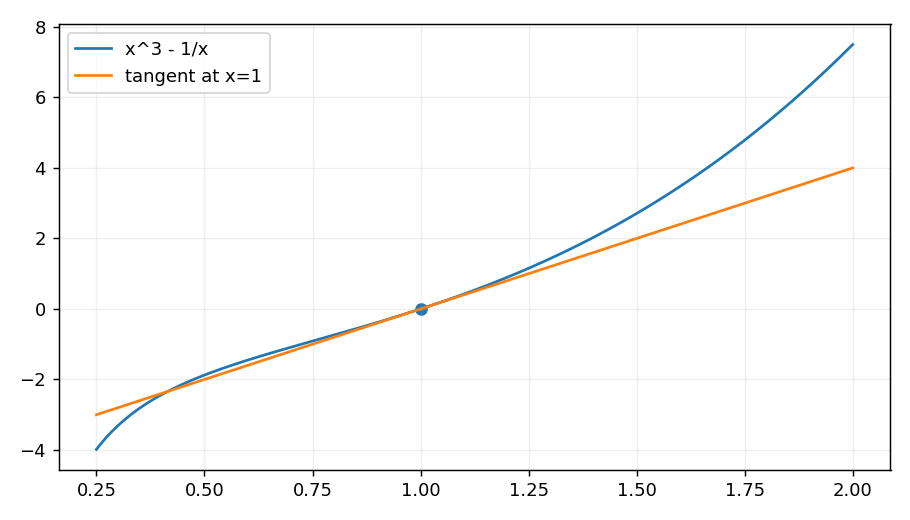

In [5]:
result = run_section("2.4", recompute=RECOMPUTE)
render_result(result)

## 2.5 — Automatic Differentiation (8 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 104 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Why is the second derivative much more expensive to compute than the first derivative?
2. After running the function for backpropagation, immediately run it again and see what
happens. Investigate.
3. In the control flow example where we calculate the derivative ofd with respect toa,
what would happen if we changed the variablea to a random vector or a matrix? At
this point, the result of the calculationf(a) is no longer a scalar. What happens to the
result? How do we analyze this?
4. Let 𝑓(𝑥) = sin(𝑥). Plot the graph of𝑓 and of its derivative𝑓′. Do not exploit the fact
that 𝑓′(𝑥) = cos(𝑥) but rather use automatic differentiation to get the result.
5. Let 𝑓(𝑥) =(( log𝑥2)· sin𝑥)+ 𝑥−1. Write out a dependency graph tracing results from
𝑥 to 𝑓(𝑥).
6. Usethechainruletocomputethederivative 𝑑𝑓𝑑𝑥 oftheaforementionedfunction, placing
each term on the dependency graph that you constructed previously.
65 Probability and Statistics
58
7. Given the graph and the intermediate derivative results, you have a number of options
when computing the gradient. Evaluate the result once starting from𝑥 to 𝑓 and once
from 𝑓 tracing back to𝑥. The path from𝑥 to 𝑓 is commonly known asforward differ-
entiation, whereas the path from𝑓 to𝑥 is known as backward differentiation.
8. When might you want to use forward, and when backward, differentiation? Hint: con-
sider the amount of intermediate data needed, the ability to parallelize steps, and the
size of matrices and vectors involved.
</pre>
</details>


### Câu 1

Đạo hàm bậc hai cần giữ/tạo đồ thị cho gradient. Với n tham số, Hessian đầy đủ
có n² phần tử và cần nhiều phép đạo hàm, nên thường tốn hơn gradient bậc một.
Hessian-vector product không cần lưu toàn Hessian và rẻ hơn đáng kể.

### Câu 2

PyTorch giải phóng intermediate sau backward mặc định; backward lại cùng graph
có thể lỗi. Muốn dùng lại graph cần `retain_graph=True` ở lần đầu, hoặc tính forward
lại. `.grad` cộng dồn nên phải zero trước bước cập nhật tiếp theo.
Notebook bắt lỗi chủ động rồi minh họa cách làm đúng.

### Câu 3

Điều kiện `while b.norm()<1000` vẫn là scalar với vector/matrix, nhưng `if b.sum()>0`
phải viết rõ; `if b>0` với nhiều phần tử không có giá trị chân lý duy nhất.
Output không scalar thì `backward()` cần gradient đầu vào cùng shape, hoặc lấy
`output.sum().backward()`; đây là vector-Jacobian product, không tự cho toàn Jacobian.
Ở một nhánh cố định, f(a)=c·a nên gradient của tổng là c ở mỗi tọa độ;
tại ranh giới đổi nhánh phải phân tích riêng.

### Câu 4

Notebook tạo x requires_grad, y=sin(x), rồi `y.sum().backward()`; vẽ y và x.grad.
Không dùng cos để tạo đường đạo hàm; cos chỉ có thể dùng làm đối chiếu sau đó.

### Câu 5

Đồ thị phụ thuộc: `x→a=x²→b=log(a)`; `x→c=sin(x)`;
`(b,c)→d=b*c`; `x→e=1/x`; `(d,e)→f=d+e`. Miền x≠0.

### Câu 6

Các đạo hàm cục bộ: a'=2x; db/da=1/a; c'=cos x;
∂d/∂b=c; ∂d/∂c=b; e'=−1/x²; ∂f/∂d=∂f/∂e=1.
Suy ra **f'=2 sin(x)/x + log(x²)cos(x) −1/x²**.

### Câu 7

Forward mode: truyền tangent dx=1 qua từng nút bằng chain rule để được công thức trên.
Reverse mode: bắt đầu adjoint f̄=1; d̄=ē=1, b̄=c, c̄=b, ā=c/a;
cộng các nhánh về x: x̄=2x·c/a + b cos x −1/x². Hai cách cho cùng kết quả;
notebook so sánh với autograd.

### Câu 8

Hàm Rⁿ→Rᵐ: forward thường phù hợp khi n nhỏ, cần khoảng n lượt cho Jacobian;
reverse phù hợp m nhỏ, cần khoảng m lượt và lưu intermediate của forward.
Loss mạng thường scalar, n lớn nên reverse mode hiệu quả. Có thể dùng JVP/VJP,
checkpointing hoặc vector hóa tùy bộ nhớ và đại lượng cần tính.

Expected second backward error: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.
Repeated backward with retain_graph accumulates grad: 8.0
Vector output=[512.0, 1024.0, 1536.0], VJP for sum=[512.0, 512.0, 512.0]
Dependency graph: x -> x^2 -> log(x^2); x -> sin(x); multiply -> +1/x -> f.


**chain_rule**

,x,autograd,forward_chain_rule,reverse_chain_rule
0,1.3,1.031045,1.031045,1.031045


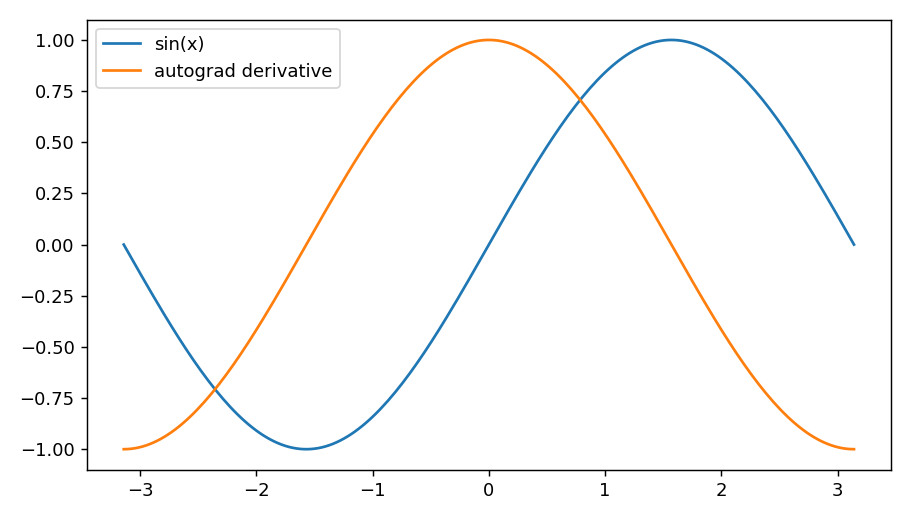

In [6]:
result = run_section("2.5", recompute=RECOMPUTE)
render_result(result)

## 2.6 — Probability and Statistics (8 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 117 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Giveanexamplewhereobservingmoredatacanreducetheamountofuncertaintyabout
the outcome to an arbitrarily low level.
2. Give an examplewhere observing more data will onlyreduce the amount of uncertainty
up to a point and then no further. Explain why this is the case and where you expect this
point to occur.
3. We empirically demonstrated convergence to the mean for the toss of a coin. Calculate
thevarianceoftheestimateoftheprobabilitythatweseeaheadafterdrawing 𝑛samples.
1. How does the variance scale with the number of observations?
2. Use Chebyshev’s inequality to bound the deviation from the expectation.
3. How does it relate to the central limit theorem?
4. Assume that we draw𝑚 samples𝑥𝑖 from a probability distribution with zero mean and
unit variance. Compute the averages𝑧𝑚
def
= 𝑚−1 ˝𝑚𝑖=1𝑥𝑖. Can we apply Chebyshev’s
inequality for every𝑧𝑚 independently? Why not?
5. Given two events with probability𝑃(A) and𝑃(B), compute upper and lower bounds
on𝑃(A∪B) and𝑃(A∩B) . Hint: graph the situation using aVenn diagram61.
6. Assumethatwehaveasequenceofrandomvariables,say 𝐴,𝐵,and 𝐶,where 𝐵onlyde-
pendson 𝐴,and 𝐶 onlydependson 𝐵,canyousimplifythejointprobability 𝑃(𝐴,𝐵,𝐶)?
Hint: this is aMarkov chain62.
7. In Section 2.6.5, assume that the outcomes of the two tests are not independent. In
particular assume that either test on its own has a false positive rate of 10% and a false
negative rate of 1%. That is, assume that𝑃(𝐷 = 1| 𝐻 = 0) = 0.1 and that𝑃(𝐷 =
0| 𝐻 = 1) = 0.01. Moreover, assume that for𝐻 = 1 (infected) the test outcomes are
78 Preliminaries
63
64
65
66
conditionally independent, i.e., that𝑃(𝐷1,𝐷 2| 𝐻 = 1) = 𝑃(𝐷1| 𝐻 = 1)𝑃(𝐷2| 𝐻 =
1) but that for healthy patients the outcomes are coupled via𝑃(𝐷1 = 𝐷2 = 1| 𝐻 =
0) = 0.02.
1. Work out the joint probability table for𝐷1 and𝐷2, given𝐻 = 0 based on the infor-
mation you have so far.
2. Derive the probability that the patient is diseased (𝐻 = 1) after one test returns
positive. You can assume the same baseline probability𝑃(𝐻 = 1) = 0.0015 as
before.
3. Derive the probability that the patient is diseased (𝐻 = 1) after both tests return
positive.
8. Assume that you are an asset manager for an investment bank and you have a choice of
stocks𝑠𝑖 to invest in. Your portfolio needs to add up to1with weights𝛼𝑖 for each stock.
The stocks have an average return𝝁 =𝐸s∼𝑃[s] and covariance𝚺 = Covs∼𝑃[s].
1. Compute the expected return for a given portfolio𝜶.
2. If you wanted to maximize the return of the portfolio, how should you choose your
investment?
3. Compute thevariance of the portfolio.
4. Formulateanoptimizationproblemofmaximizingthereturnwhilekeepingthevari-
anceconstrainedtoanupperbound. ThisistheNobel-Prizewinning Markovitzport-
folio63 (Mangram, 2013). To solve it you will need a quadratic programming solver,
something way beyond the scope of this book.
</pre>
</details>


### Câu 1

Với các lần tung đồng xu IID có xác suất p cố định, càng nhiều mẫu càng xác định
chính xác p: Var(p̂)=p(1−p)/n→0. Đây là bất định về tham số, không phải biết
chắc kết quả của lần tung tiếp theo.

### Câu 2

Ngay khi biết p=0.5 chính xác, một lần tung tiếp theo vẫn ngẫu nhiên; bất định
không giảm về 0 chỉ nhờ thêm dữ liệu quá khứ. Phân biệt bất định tham số và nhiễu vốn có.

### Câu 3

Với Bernoulli IID: Var(p̂)=p(1−p)/n, giảm theo 1/n; độ lệch chuẩn theo 1/√n.
Chebyshev: `P(|p̂−p|≥ε)≤p(1−p)/(nε²)`. CLT cho
`√n(p̂−p)→N(0,p(1−p))`, giúp xấp xỉ xác suất chặt hơn khi điều kiện phù hợp.

### Câu 4

Nếu mẫu IID mean 0, variance 1: Var(z_m)=1/m và mỗi m riêng đều có cận
`P(|z_m|≥ε)≤1/(mε²)`. Nhưng zₘ dùng chung các mẫu với zₘ₊₁, nên các sự kiện
không độc lập; không nhân xác suất/cận như thể độc lập. Nếu mẫu không độc lập,
phải thêm covariance, không mặc định Var=1/m.

### Câu 5

Đặt a=P(A), b=P(B): `max(a,b)≤P(A∪B)≤min(1,a+b)`;
`max(0,a+b−1)≤P(A∩B)≤min(a,b)`. Từ công thức cộng xác suất và sự bao hàm tập hợp.

### Câu 6

Chuỗi Markov A→B→C: `P(A,B,C)=P(A)P(B|A)P(C|B)` vì C độc lập có điều kiện với A khi biết B.

### Câu 7

Đây là phép tính xác suất giả định của bài tập, không phải hướng dẫn xét nghiệm thực tế.
Khi H=0: bảng (D1,D2) có `(1,1)=0.02`, `(1,0)=0.08`, `(0,1)=0.08`,
`(0,0)=0.82`. Khi H=1, xác suất cả hai dương là 0.99²=0.9801.
Với prior 0.0015:

- Sau một dương: `0.99·0.0015/(0.99·0.0015+0.1·0.9985)`.
- Sau hai dương: `0.9801·0.0015/(0.9801·0.0015+0.02·0.9985)`.

Notebook tính giá trị số; không dùng 0.1² cho người khỏe vì đề nói hai kết quả có phụ thuộc.

### Câu 8

Đây là bài toán toán học danh mục giả định. Với tổng αᵢ=1:
E[return]=αᵀμ; Var(return)=αᵀΣα. Nếu α≥0 và chỉ tối đa kỳ vọng, đặt toàn bộ vào
tài sản có μ lớn nhất (chia tùy ý nếu đồng hạng). Nếu cho short vô hạn và không
ràng buộc rủi ro, bài toán có thể không bị chặn. Có giới hạn rủi ro v:
`max αᵀμ`, subject to `1ᵀα=1, αᵀΣα≤v` và α≥0 nếu không cho short.
Đề chỉ yêu cầu lập bài toán, không yêu cầu giải quadratic program.

**coin_variance**

,n,empirical_variance,theoretical_variance
0,10,0.024440,0.025000
1,100,0.002610,0.002500
2,1000,0.000247,0.000250
3,10000,0.000025,0.000025


**bayes_exercise**

,observations,posterior
0,one positive,0.014654
1,"two positives, correlated healthy tests",0.068570


**joint_given_healthy**

,D1,D2,probability
0,0,0,0.82
1,0,1,0.08
2,1,0,0.08
3,1,1,0.02


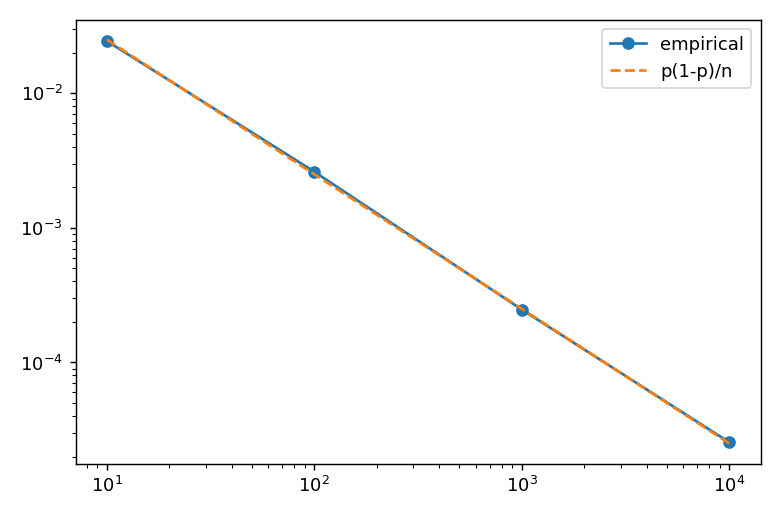

In [7]:
result = run_section("2.6", recompute=RECOMPUTE)
render_result(result)

## 2.7 — Documentation

PDF không có Exercises đánh số ở mục này. Notebook minh họa `help`, docstring và
chữ ký hàm để luyện tra API, không tự thêm chúng thành câu hỏi của sách.

In [8]:
result = run_section("2.7", recompute=RECOMPUTE)
render_result(result)

torch.add docstring:

add(input, other, *, alpha=1, out=None) -> Tensor

Adds :attr:`other`, scaled by :attr:`alpha`, to :attr:`input`.

.. math::
    \text{{out}}_i = \text{{input}}_i + \text{{alpha}} \times \text{{other}}_i


Supports :ref:`broadcasting to a common shape <broadcasting-semantics>`,
:ref:`type promotion <type-promotion-doc>`, and integer, float, and complex inputs.

Args:
    input (Tensor): the input tensor.
    other (Tensor or Number): the tensor or number to add to :attr:`input`.

Keyword arguments:
    alpha (Number): the multiplier for :attr:`other`.
    out (Tensor, optional): the output tensor.

Examples::

    >>> a = torch.randn(4)
    >>> a
    tensor([ 0.0202,  1.0985,  1.3506, -0.6056])
    >>> torch.add(a, 20)
    tensor([ 20.0202,  21.0985,  21.3506,  19.3944])

    >>> b = torch.randn(4)
    >>> b
    tensor([-0.9732, -0.3497,  0.6245,  0.4022])
    >>> c = torch.randn(4, 1)
    >>> c
    tensor([[ 0.3743],
            [-1.7724],
            [-0.5811],
